In [54]:
# importing required libraries
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Wczytanie danych z pliku CSV
data = pd.read_csv('VLagun_Phys_Years3.csv')

# Wyświetlenie 5 pierwszych wierszy
print(data.head())

# Podział na zmienne objaśniające (X) i zmienną objaśnianą (Y)
X = data.iloc[:, :-1]
Y = data.iloc[:, -1]

seed = 7

# Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=seed)

# Wyświetlenie wymiarów zbiorów
print(X_train.shape, X_test.shape)

        PSU     O2  temp.    SS    DOC    TPOC  Windspeedinsitu  Depth  Years
0  3.757624   9.46   18.3  52.0  7.500  8.5650              3.5    3.3      0
1  3.504707   9.89   19.1  50.0  7.860  8.5200              0.0    3.6      0
2  3.757624   9.66   18.1  59.0  8.172  8.4915              1.0    3.4      0
3  3.107266  10.36   19.5  46.0  7.848  8.8320              0.0    2.9      0
4  2.619498  11.56   19.0  42.0  7.536  9.2400              0.0    3.0      0
(84, 8) (36, 8)


In [55]:
model = GaussianNB()

# fit the model with the training data
model.fit(X_train, y_train)

# predict the target on the train dataset
predict_train = model.predict(X_train)
print('Target on train data', predict_train)

# Accuray Score on train dataset
accuracy_train = accuracy_score(y_train, predict_train)
print('accuracy_score on train dataset : ', accuracy_train)

# fit the model with the test data
model.fit(X_test, y_test)

# predict the target on the test dataset
predict_test = model.predict(X_test)
print('Target on test data', predict_test)

# Accuracy Score on test dataset
accuracy_test = accuracy_score(y_test, predict_test)
print('accuracy_score on test dataset : ', accuracy_test)

Target on train data [1 0 1 0 1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 1 0 0 1 1 0 0 1 0
 1 1 1 0 0 0 1 1 1 0 1 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 1 1 0 1 1 1
 0 0 1 1 0 1 1 0 1 0]
accuracy_score on train dataset :  0.9404761904761905
Target on test data [1 1 1 1 1 0 1 1 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 1 0 1]
accuracy_score on test dataset :  0.8888888888888888


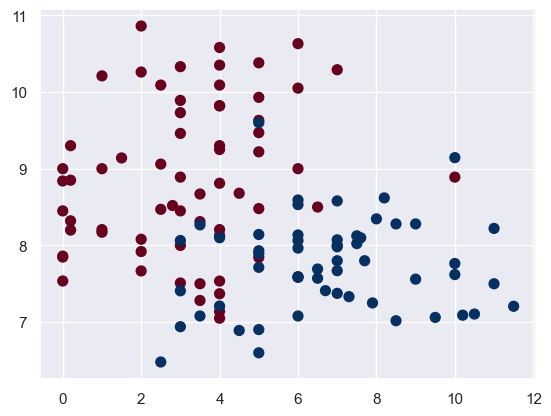

In [56]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()

# Zmień zmienne (obiekty), wybierając ich lokalizację w ramce danych.
# Na przykład: SS i TPOC, Depth i PSU itp.
df = pd.read_csv('VLagun_Phys_Years3.csv')
X = df.iloc[:, [6, 4]].values       # feature metric
y = df.iloc[:, 8].values          # dependent variable

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='RdBu')
plt.show()

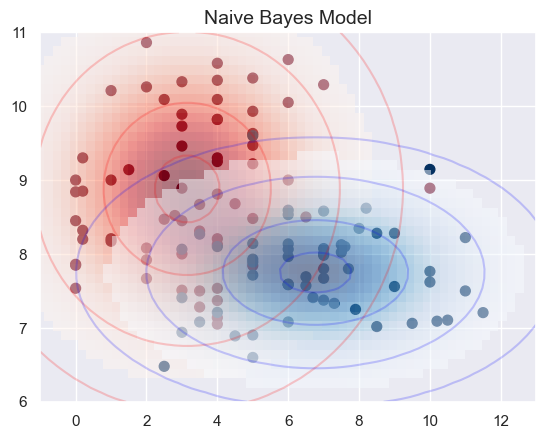

In [57]:
fig, ax = plt.subplots()

ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='RdBu')
ax.set_title('Naive Bayes Model', size=14)

xlim = (-1, 13)
ylim = (6, 11)

xg = np.linspace(xlim[0], xlim[1], 60)
yg = np.linspace(ylim[0], ylim[1], 40)
xx, yy = np.meshgrid(xg, yg)
Xgrid = np.vstack([xx.ravel(), yy.ravel()]).T

for label, color in enumerate(['red', 'blue']):
    mask = (y == label)
    mu, std = X[mask].mean(0), X[mask].std(0)
    P = np.exp(-0.5 * (Xgrid - mu) ** 2 / std ** 2).prod(1)
    Pm = np.ma.masked_array(P, P < 0.03)
    
    ax.pcolormesh(xg, yg, Pm.reshape(xx.shape), alpha=0.5,
                  cmap=color.title() + 's', shading='auto')
    
    ax.contour(xx, yy, P.reshape(xx.shape),
               levels=[0.01, 0.1, 0.5, 0.9],
               colors=color, alpha=0.2)

ax.set(xlim=xlim, ylim=ylim)

plt.show()

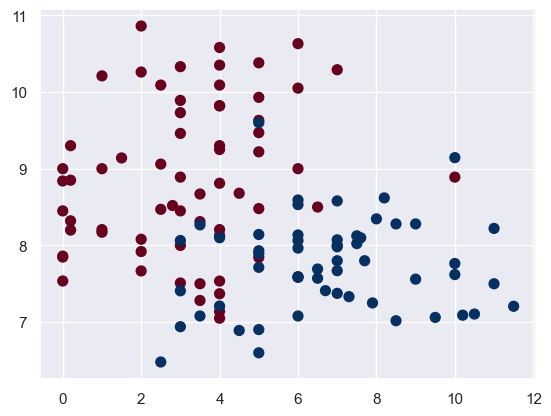

[[1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]]


In [58]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB

# Inicjalizacja i dopasowanie modelu
model = GaussianNB()
model.fit(X, y)

# Generowanie nowych danych i przewidywanie etykiet
rng = np.random.RandomState(0)
Xnew = [-6, -14] + [14, 18] * rng.rand(2000, 2)
ynew = model.predict(Xnew)

# Wykreślanie danych, aby zobaczyć granicę decyzyjną
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='RdBu')
lim = plt.axis()
plt.scatter(Xnew[:, 0], Xnew[:, 1], c=ynew, s=20, cmap='RdBu', alpha=0.1)
plt.axis(lim)
plt.show()

# Wykorzystanie metody predict_proba do klasyfikacji probabilistycznej
yprob = model.predict_proba(Xnew)
print(yprob[-8:].round(2))

In [59]:
yprob = model.predict_proba(Xnew)
yprob[-8:].round(2)

array([[1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.]])